# How To Map The Coffee Divide: Producers, Drinkers And The Surprising Truth

*A Python tutorial mapping global coffee production and consumption with Plotly choropleth and bubble charts*

**Data:** coffee-bean-production.csv (Our World in Data / FAO), https://ourworldindata.org/grapher/coffee-bean-production, data to 2022; coffee-consumption-per-capita.csv (ICO/Euromonitor compiled)

**Article:** (link added when the article is published)

Run the cells in order. Dataset files are in the same folder as this notebook.

In [1]:
import plotly.io as pio
pio.renderers.default = "notebook_connected+png"  # interactive in Jupyter, image on GitHub

### The Datasets

Two datasets drive this analysis.

In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Production data (Our World in Data / FAO)
prod = pd.read_csv('coffee-bean-production.csv')
# Filter to country-level rows — remove regional aggregates with OWID_ codes
prod = prod[prod['Code'].str.match(r'^[A-Z]{3}$', na=False)]

# Consumption data (ICO/Euromonitor compiled)
cons = pd.read_csv('coffee-consumption-per-capita.csv')

print(prod.shape, cons.shape)
print(prod[prod['Year'] == 2022].sort_values('Green coffee - Production (tonnes)', ascending=False).head(5))

(5095, 4) (70, 5)
         Entity Code  Year  Green coffee - Production (tonnes)
600      Brazil  BRA  2022                          3179341.00
6988    Vietnam  VNM  2022                          1953990.10
3162  Indonesia  IDN  2022                           774960.50
1222   Colombia  COL  2022                           665015.94
2214   Ethiopia  ETH  2022                           545566.40


### Chart 1: The Diverging Map — Who Grows vs Who Drinks

The first question is straightforward: for each country, is it a net producer relative to its population, or a net consumer?

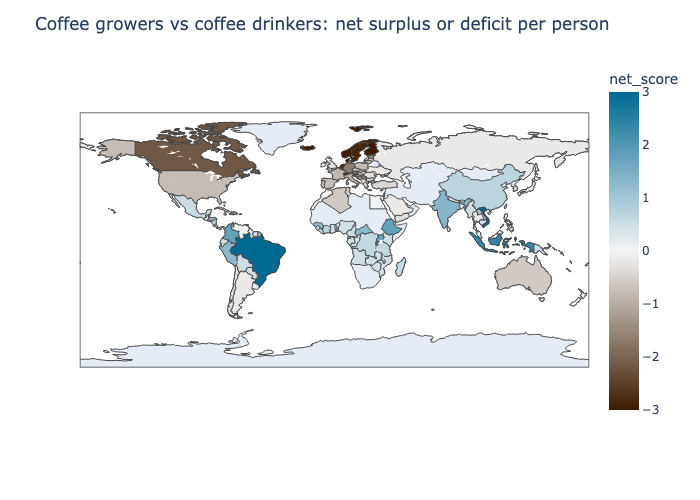

In [3]:
import numpy as np

# z-score helper (no scipy dependency needed)
def zscore(s):
    return (s - s.mean()) / s.std()

prod_2022 = prod[prod['Year'] == 2022].copy()
prod_col = 'Green coffee - Production (tonnes)'

# Merge production and consumption on ISO3 code
merged = prod_2022.merge(cons[['Code','consumption_kg_per_capita']], on='Code', how='outer')
merged[prod_col] = merged[prod_col].fillna(0)
merged['consumption_kg_per_capita'] = merged['consumption_kg_per_capita'].fillna(0)

# Z-score both metrics, then compute net difference
merged['net_score'] = zscore(merged[prod_col]) - zscore(merged['consumption_kg_per_capita'])

# Diverging choropleth
fig = px.choropleth(
    merged,
    locations='Code',
    color='net_score',
    color_continuous_scale=[[0,'#3D1C02'],[0.5,'#F5F5F5'],[1,'#006994']],
    range_color=[-3, 3],
    hover_name='Entity',
)
fig.update_layout(title='Coffee growers vs coffee drinkers: net surplus or deficit per person')
fig.show()

### Chart 2: Where the Coffee Actually Comes From

The second question is about concentration. How much of global production sits in just a few countries?

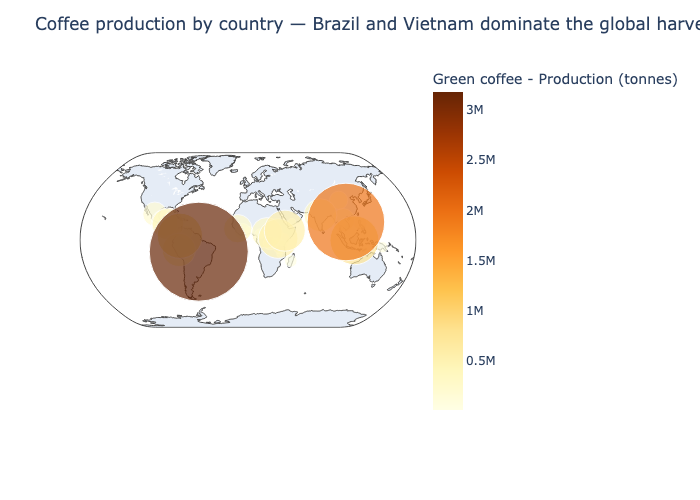

In [4]:
prod_2022_top = prod_2022[prod_2022['Green coffee - Production (tonnes)'] > 10000]

fig = px.scatter_geo(
    prod_2022_top.sort_values('Green coffee - Production (tonnes)', ascending=True),
    locations='Code',
    size='Green coffee - Production (tonnes)',
    color='Green coffee - Production (tonnes)',
    hover_name='Entity',
    color_continuous_scale='YlOrBr',
    size_max=70,
    projection='natural earth',
)
fig.update_layout(title='Coffee production by country — Brazil and Vietnam dominate the global harvest')
fig.show()

### Chart 3: The Rank Mismatch

The final chart puts the divide in its starkest form. When you rank countries by absolute production and separately by per-capita consumption, do the same countries appear near the top?

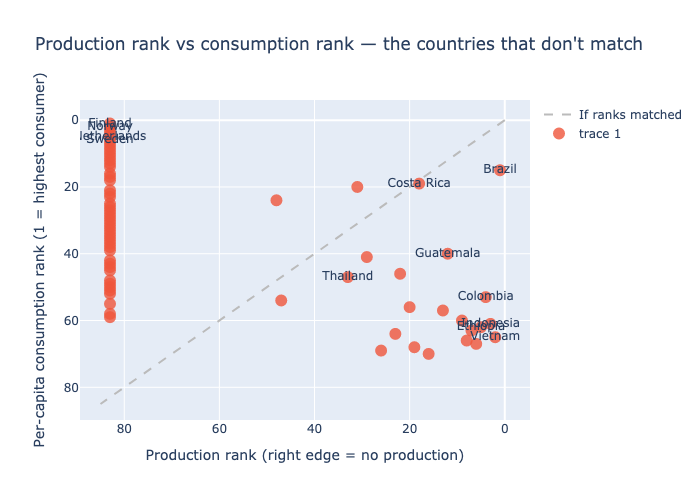

In [5]:
# Rank all 78 producers by absolute output
prod_ranked = prod_2022.sort_values(
    'Green coffee - Production (tonnes)', ascending=False
).reset_index(drop=True)
prod_ranked['prod_rank'] = prod_ranked.index + 1

# Rank all 70 countries by per-capita consumption
cons_ranked = cons.sort_values(
    'consumption_kg_per_capita', ascending=False
).reset_index(drop=True)
cons_ranked['cons_rank'] = cons_ranked.index + 1

# Merge: non-producers get a rank beyond the last actual producer
scatter = cons_ranked.merge(prod_ranked[['Code','prod_rank']], on='Code', how='left')
scatter['prod_rank'] = scatter['prod_rank'].fillna(83)

# Label key outliers — blank string for all other points
label_codes = {'BRA', 'VNM', 'COL', 'IDN', 'ETH', 'FIN', 'NOR', 'NLD', 'SWE', 'GTM', 'CRI', 'THA'}
scatter['label'] = scatter.apply(lambda r: r['Entity'] if r['Code'] in label_codes else '', axis=1)

# Scatter with diagonal reference line
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=[0, 85], y=[0, 85],
    mode='lines', line=dict(dash='dash', color='#BBBBBB'),
    name='If ranks matched'
))
fig.add_trace(go.Scatter(
    x=scatter['prod_rank'], y=scatter['cons_rank'],
    mode='markers+text',
    text=scatter['label'],  # labels for key outliers
    marker=dict(size=12, opacity=0.8),
))
fig.update_layout(
    title="Production rank vs consumption rank — the countries that don't match",
    xaxis=dict(title='Production rank (right edge = no production)', autorange='reversed'),
    yaxis=dict(title='Per-capita consumption rank (1 = highest consumer)', autorange='reversed'),
)
fig.show()